**Checkpoint de 100 posições:** esta análise usa legacy/checkpoints/HardPos_/gpt_model_HardPos_.pt. Para o modelo de 10 posições, abra HardPos_speed_cells_contexto10.ipynb.

# Busca exploratória de speed cells no HardPos

A rede recebe apenas PS. Para cada instante amostrado, fornecemos os 99 PS até aquele instante e extraímos a ativação da última posição, com atenção causal. Comparamos a ativação à magnitude da velocidade no mesmo instante e às médias dos últimos 3, 5 e 10 registros. O próximo PS não entra na inferência. Os registros têm intervalos de tempo variáveis: as médias curtas são por amostra, não por segundos.

A divisão é a mesma fronteira temporal do treino (80%/20%). As janelas de validação ficam inteiramente após essa fronteira. Selecionamos dimensões somente no treino e verificamos as mesmas no trecho reservado. Correlações e curvas aqui são de ativações artificiais, não taxas de disparo de neurônios biológicos.

In [1]:
%matplotlib inline
from pathlib import Path
import json, math, pickle
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from scipy.stats import spearmanr, rankdata
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
from IPython.display import display

root = Path('.')
df = pd.read_parquet(root / 'bert_trainset_squared_25.gzip')
with (root / 'ps_to_psid.pkl').open('rb') as f:
    ps_to_psid = pickle.load(f)
ids = df['position_state'].map(ps_to_psid).to_numpy()
assert np.isfinite(ids).all()
ids = ids.astype(np.int64)
pos = np.stack(df['pos'].to_numpy()).astype(float)
vel = np.stack(df['vel'].to_numpy()).astype(float)
speed = np.linalg.norm(vel, axis=1)
times = df['t'].to_numpy(float)
assert np.isfinite(pos).all() and np.isfinite(speed).all()
window = 99
split_index = int(.8 * len(ids))
# Amostragem reprodutível; cada janela usada na validação começa após a fronteira.
train_t = np.arange(window - 1, split_index, 4)
test_t = np.arange(split_index + window - 1, len(ids), 3)
t_index = np.r_[train_t, test_t]
split = np.array(['treino'] * len(train_t) + ['teste'] * len(test_t))
contexts = ids[t_index[:, None] - np.arange(window - 1, -1, -1)[None, :]]
assert contexts.shape == (len(t_index), window)
assert (test_t - window + 1 >= split_index).all()
assert (train_t < split_index).all()
print('Janelas:', len(train_t), 'treino;', len(test_t), 'teste')
print('Mediana dt:', np.median(np.diff(times)), 's; intervalo:', np.min(np.diff(times)), 'a', np.max(np.diff(times)), 's')
print('Velocidade:', speed.min(), 'a', speed.max())
from project_support.csv_runs import notebook_csv_path


Janelas: 2603 treino; 843 teste
Mediana dt: 0.1500000000005457 s; intervalo: 0.049999999999954525 a 3.450000000012551 s
Velocidade: 0.002644717601544832 a 0.3488879735747443


In [2]:
training_nb = json.loads((root / 'navitran_vizz_reboot_gpt_squared_25_span.ipynb').read_text(encoding='utf-8'))
for cell_no in (21, 23):
    exec(''.join(training_nb['cells'][cell_no]['source']), globals())
pad_id = int(ids.max()) + 1
model = TrajectoryBERT_HardPos(
    pad_id + 1, embed_size=16, num_layers=1, num_heads=1, hidden_dim=32,
    dropout=.2, pad_token_id=pad_id, max_len=100, causal=True,
)
model.load_state_dict(torch.load(root / 'legacy/checkpoints/HardPos_/gpt_model_HardPos_.pt', map_location='cpu', weights_only=True))
model.eval()
torch.set_num_threads(min(4, torch.get_num_threads()))
layer = model.encoder.layers[0]

@torch.inference_mode()
def last_activations(tokens):
    emb = model.embedding(tokens)
    x = model.position_embedding(emb)
    q, k, v = F.linear(x, layer.self_attn.in_proj_weight, layer.self_attn.in_proj_bias).chunk(3, -1)
    mask = model._causal_mask(tokens.shape[1], tokens.device)
    attn, _ = layer.self_attn(x, x, x, attn_mask=mask, need_weights=False)
    residual1 = x + layer.dropout1(attn)
    norm1 = layer.norm1(residual1)
    ff1 = layer.linear1(norm1)
    ff_act = layer.activation(ff1)
    ff2 = layer.linear2(layer.dropout(ff_act))
    residual2 = norm1 + layer.dropout2(ff2)
    norm2 = layer.norm2(residual2)
    reps = {
        'token_embedding': emb, 'embedding_plus_position': x,
        'query_projection': q, 'key_projection': k, 'value_projection': v,
        'attention_output': attn, 'attention_residual': residual1,
        'attention_norm': norm1, 'ff_linear1': ff1,
        'ff_activation': ff_act, 'ff_linear2': ff2,
        'ff_residual': residual2, 'encoder_output': norm2,
    }
    return {name: a[:, -1].numpy() for name, a in reps.items()}, norm2

blocks = {}
for start in range(0, len(contexts), 32):
    batch = torch.from_numpy(contexts[start:start+32])
    reps, encoder_sequence = last_activations(batch)
    if start == 0:
        with torch.inference_mode():
            torch.testing.assert_close(model.fc_out(encoder_sequence[:, -1]),
                                       model(batch)[:, -1], atol=1e-5, rtol=1e-5)
    for name, values in reps.items():
        blocks.setdefault(name, []).append(values)
features = {}
for name, chunks in blocks.items():
    a = np.concatenate(chunks)
    for d in range(a.shape[1]):
        features[f'{name}__d{d:02d}'] = a[:, d]
features_df = pd.DataFrame(features)
meta = pd.DataFrame({
    'split': split, 't_index': t_index, 'time_s': times[t_index],
    'x': pos[t_index, 0], 'y': pos[t_index, 1],
    'vx': vel[t_index, 0], 'vy': vel[t_index, 1],
    'speed_instant': speed[t_index], 'last_ps_id': ids[t_index],
})
for width in (3, 5, 10):
    meta[f'speed_last_{width}'] = [speed[t-width+1:t+1].mean() for t in t_index]
activations = pd.concat([meta, features_df], axis=1)
activations.to_parquet(root / 'legacy/analysis/HardPos_speed_cells_ativacoes.parquet', index=False)
print('Dimensões:', len(features), '| amostras:', len(activations))
display(meta.groupby('split')[['speed_instant','speed_last_5']].agg(['mean','std','min','max']).round(3))

/home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Dimensões: 240 | amostras: 3446


speed_instant                      speed_last_5                     
                mean    std    min    max         mean    std    min    max
split                                                                      
teste          0.123  0.053  0.010  0.320        0.124  0.042  0.032  0.305
treino         0.124  0.052  0.004  0.332        0.124  0.041  0.031  0.284

## Correlação bruta e após controlar posição e direção

Para o controle, ajustamos separadamente em cada partição uma regressão de referência com células espaciais de 10×10 e oito faixas de direção. Correlacionamos os resíduos da velocidade e da ativação. Isso é um controle exploratório: pode remover sinais reais associados ao comportamento e não substitui réplicas independentes. A direção vem do vetor de velocidade do dataset, mas nunca é entrada da rede.

In [3]:
def spatial_direction_design(frame):
    # Limites espaciais fixados em todo o dataset para usar o mesmo sistema de células.
    xy = frame[['x','y']].to_numpy(float)
    low = pos.min(axis=0)
    high = pos.max(axis=0)
    cell = np.clip(((xy-low)/(high-low+1e-12)*10).astype(int), 0, 9)
    loc = cell[:,1]*10+cell[:,0]
    angle = np.arctan2(frame['vy'].to_numpy(), frame['vx'].to_numpy())
    direction = np.floor((angle+np.pi)/(2*np.pi)*8).astype(int).clip(0,7)
    return np.column_stack([np.ones(len(frame)), np.eye(100)[loc], np.eye(8)[direction]])

feature_cols = list(features)
feature_matrix = activations[feature_cols].to_numpy(float)
tr = np.flatnonzero(split == 'treino')
te = np.flatnonzero(split == 'teste')
partitions = {'treino':tr, 'teste':te}
windows = ['speed_instant','speed_last_3','speed_last_5','speed_last_10']
residual_features = {}
residual_speeds = {}
for name, index in partitions.items():
    design = spatial_direction_design(meta.iloc[index])
    # Pequena regularização para células raras sem comprometer a remoção do efeito principal.
    regularizer = np.sqrt(1e-3)*np.eye(design.shape[1])
    coefficient = np.linalg.lstsq(np.vstack([design,regularizer]),
                                  np.vstack([feature_matrix[index],np.zeros((design.shape[1],feature_matrix.shape[1]))]),
                                  rcond=None)[0]
    residual_features[name] = feature_matrix[index] - design@coefficient
    for target in windows:
        y = meta[target].to_numpy(float)[index]
        beta = np.linalg.lstsq(np.vstack([design,regularizer]),
                               np.r_[y,np.zeros(design.shape[1])], rcond=None)[0]
        residual_speeds[(name,target)] = y-design@beta

rows = []
for name, index in partitions.items():
    for target in windows:
        y = meta[target].to_numpy(float)[index]
        ry = residual_speeds[(name,target)]
        for j, feature in enumerate(feature_cols):
            raw = spearmanr(feature_matrix[index,j], y).statistic if np.std(feature_matrix[index,j])>1e-12 else np.nan
            adj = spearmanr(residual_features[name][:,j], ry).statistic if np.std(residual_features[name][:,j])>1e-12 else np.nan
            rows.append((feature,feature.rsplit('__d',1)[0],int(feature.rsplit('__d',1)[1]),name,target,raw,adj))
scores = pd.DataFrame(rows,columns=['feature','representation','dimension','split','target','rho_raw','rho_adjusted'])
scores.to_csv(notebook_csv_path('HardPos_speed_cells', 'HardPos_speed_cells_scores.csv'),index=False)
# Seleção apenas no treino, velocidade instantânea e médias curtas.
train_scores = scores[scores.split=='treino'].copy()
train_scores['abs_adj'] = train_scores.rho_adjusted.abs()
selected_rows = train_scores.sort_values('abs_adj',ascending=False).drop_duplicates('feature').head(20)
selected = selected_rows.drop_duplicates('representation').head(6)[['feature','target']]
print('Top 6 por representação, escolhidos só no treino:')
for feature,target in selected.itertuples(index=False):
    pair = scores[(scores.feature==feature)&(scores.target==target)].set_index('split')
    print(feature,target,'ajustado: treino',round(pair.loc['treino','rho_adjusted'],3),
          'teste',round(pair.loc['teste','rho_adjusted'],3),
          '| bruto: treino',round(pair.loc['treino','rho_raw'],3),
          'teste',round(pair.loc['teste','rho_raw'],3))


Top 6 por representação, escolhidos só no treino:
key_projection__d15 speed_last_3 ajustado: treino 0.064 teste 0.071 | bruto: treino 0.035 teste 0.025
embedding_plus_position__d01 speed_instant ajustado: treino -0.063 teste -0.022 | bruto: treino -0.035 teste -0.03
token_embedding__d01 speed_instant ajustado: treino -0.063 teste -0.022 | bruto: treino -0.035 teste -0.03
attention_residual__d01 speed_instant ajustado: treino -0.062 teste -0.047 | bruto: treino -0.036 teste -0.052
ff_linear1__d26 speed_instant ajustado: treino 0.056 teste 0.001 | bruto: treino 0.044 teste 0.021
value_projection__d14 speed_instant ajustado: treino -0.056 teste -0.046 | bruto: treino -0.049 teste -0.063


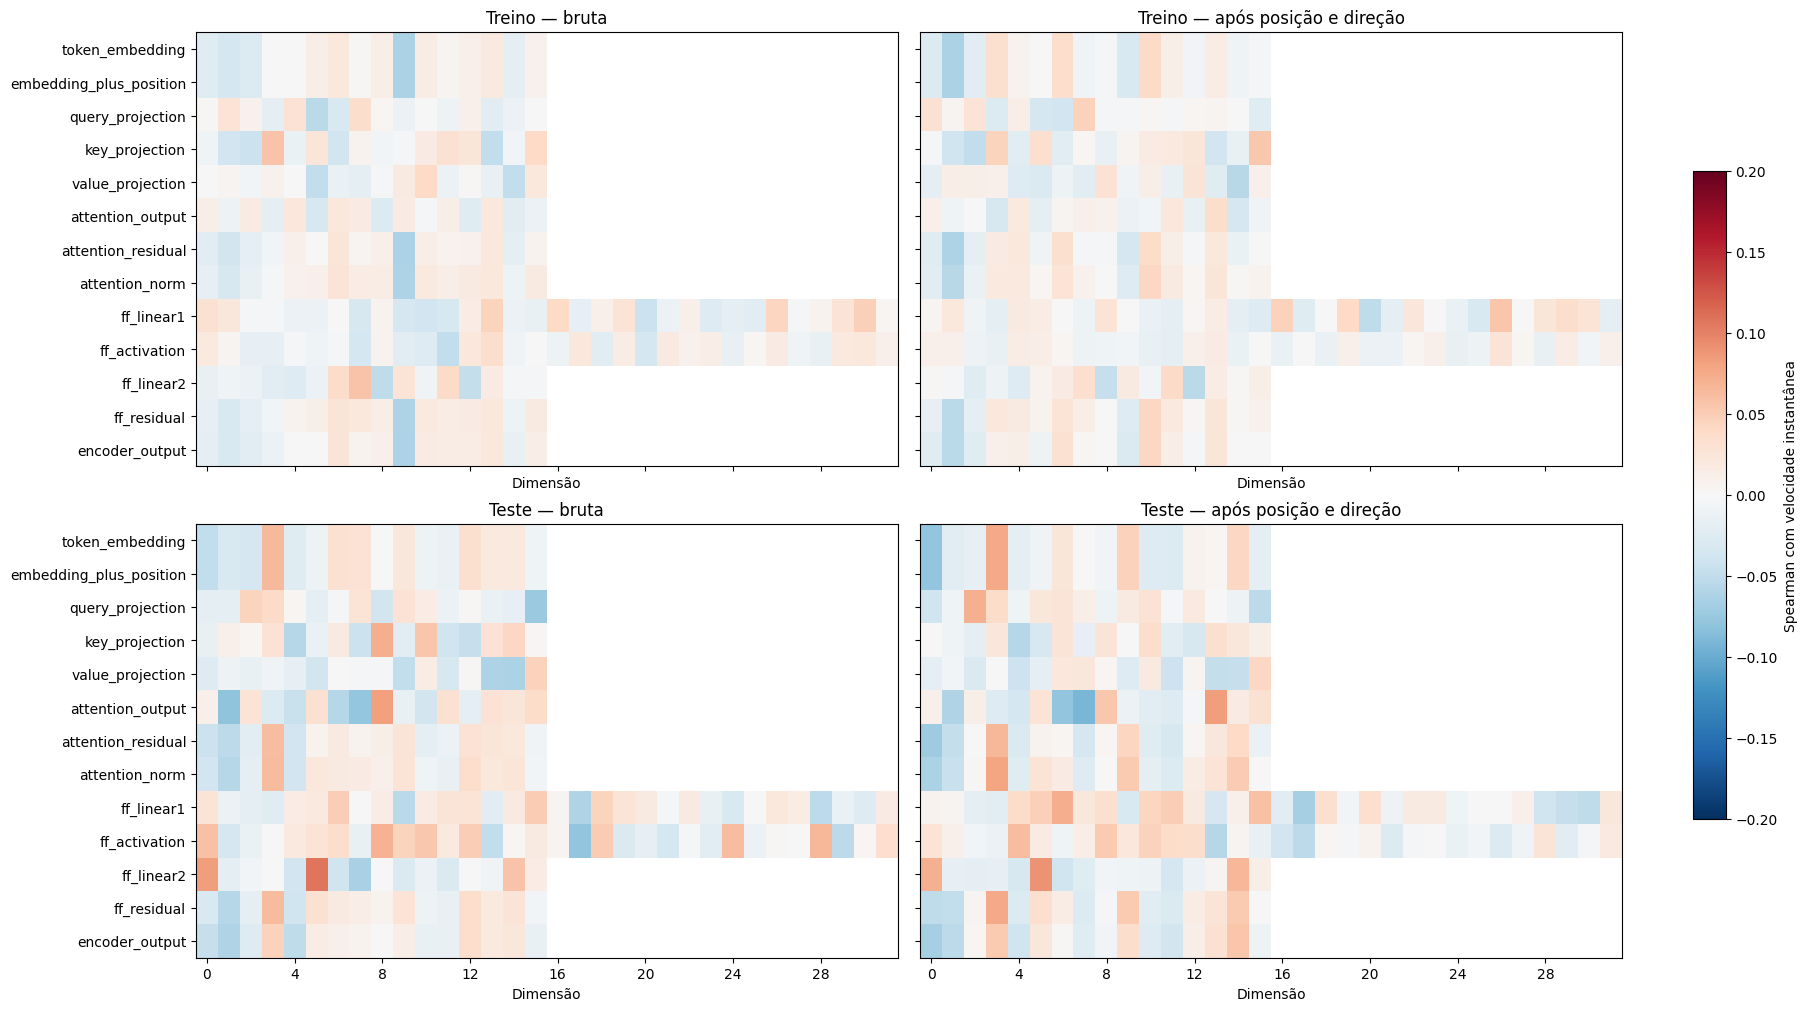

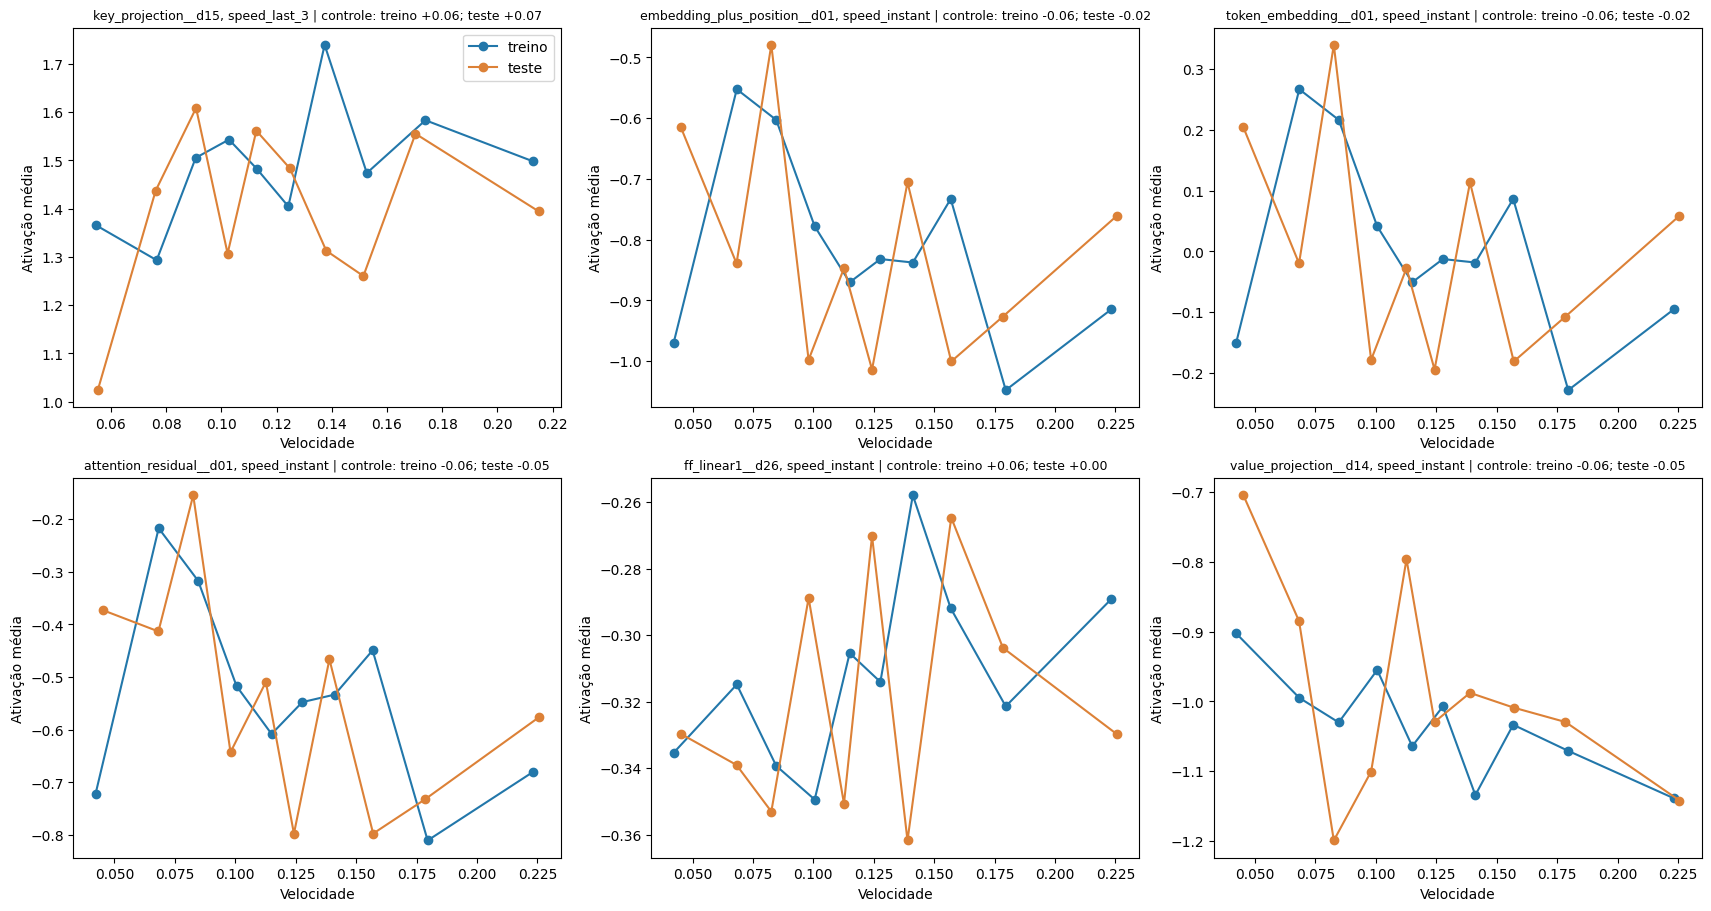

In [4]:
# Mapas para velocidade instantânea; cinza = dimensão indisponível.
order = list(dict.fromkeys(scores['representation']))
subset = scores[scores.target=='speed_instant']
limit = max(.2, float(np.nanmax(np.abs(subset[['rho_raw','rho_adjusted']].to_numpy()))))
fig, axes = plt.subplots(2,2,figsize=(18,10),sharex=True,sharey=True,constrained_layout=True)
for row, name in enumerate(('treino','teste')):
    for col, metric in enumerate(('rho_raw','rho_adjusted')):
        matrix = np.full((len(order),32),np.nan)
        for record in subset[subset.split==name].itertuples():
            matrix[order.index(record.representation),record.dimension] = getattr(record,metric)
        im = axes[row,col].imshow(matrix,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
        axes[row,col].set_title(f'{name.capitalize()} — '+('bruta' if col==0 else 'após posição e direção'))
        axes[row,col].set_yticks(range(len(order)),order)
        axes[row,col].set_xticks(np.arange(0,32,4))
        axes[row,col].set_xlabel('Dimensão')
fig.colorbar(im,ax=axes,label='Spearman com velocidade instantânea',shrink=.7)
(root/'imgs').mkdir(exist_ok=True)
fig.savefig(root/'imgs/hardpos_speed_cells_mapa.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

fig,axes=plt.subplots(2,3,figsize=(17,9),constrained_layout=True)
for ax,(feature,target) in zip(axes.flat,selected.itertuples(index=False)):
    for name,color in [('treino','#2277aa'),('teste','#dc8137')]:
        part=activations[activations.split==name]
        x=part[target].to_numpy(float)
        a=part[feature].to_numpy(float)
        edges=np.quantile(x,np.linspace(0,1,11))
        mids=[]; means=[]
        for left,right in zip(edges[:-1],edges[1:]):
            keep=(x>=left)&(x<=right if right==edges[-1] else x<right)
            if keep.sum()>=5:
                mids.append(x[keep].mean()); means.append(a[keep].mean())
        ax.plot(mids,means,marker='o',label=name,color=color)
    pair=scores[(scores.feature==feature)&(scores.target==target)].set_index('split')
    ax.set_title(f'{feature}, {target} | controle: treino {pair.loc["treino","rho_adjusted"]:+.2f}; teste {pair.loc["teste","rho_adjusted"]:+.2f}',fontsize=9)
    ax.set_xlabel('Velocidade'); ax.set_ylabel('Ativação média')
axes.flat[0].legend()
fig.savefig(root/'imgs/hardpos_speed_cells_curvas.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

## As 32 unidades do feedforward

A ativação depois da não linearidade do feedforward é a representação mais próxima de uma coleção de unidades individuais. As projeções de query, key e value são componentes internas da atenção e não devem ser chamadas isoladamente de speed cells. A unidade mostrada a seguir é escolhida somente pelo treino.

,feature,target,split,rho_raw,rho_adjusted
411,ff_activation__d11,speed_last_3,treino,-0.045,-0.030
1371,ff_activation__d11,speed_last_3,teste,0.041,0.069


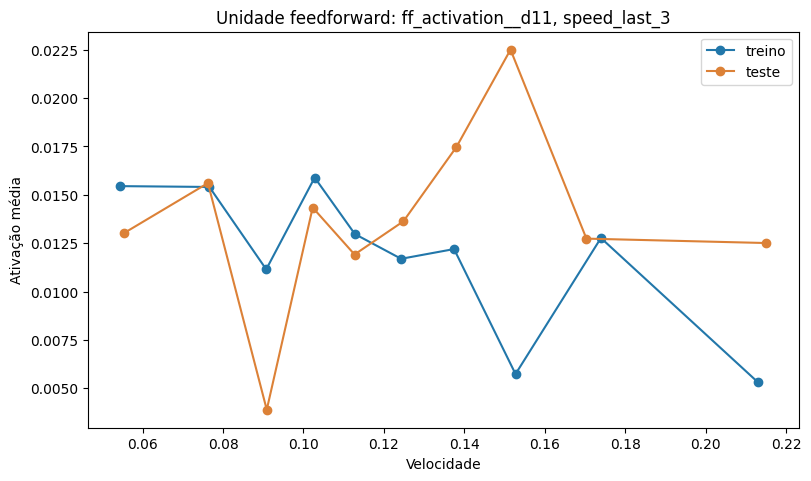

In [5]:
ff_train = scores[(scores.split=='treino') & (scores.representation=='ff_activation')].copy()
ff_train['abs_adj'] = ff_train.rho_adjusted.abs()
ff_best = ff_train.sort_values('abs_adj',ascending=False).iloc[0]
ff_feature, ff_target = ff_best['feature'], ff_best['target']
ff_pair = scores[(scores.feature==ff_feature)&(scores.target==ff_target)]
display(ff_pair[['feature','target','split','rho_raw','rho_adjusted']].round(3))
fig,ax=plt.subplots(figsize=(8,4.7),constrained_layout=True)
for name,color in [('treino','#2277aa'),('teste','#dc8137')]:
    part=activations[activations.split==name]
    x=part[ff_target].to_numpy(float)
    a=part[ff_feature].to_numpy(float)
    edges=np.quantile(x,np.linspace(0,1,11))
    mids=[]; means=[]
    for left,right in zip(edges[:-1],edges[1:]):
        keep=(x>=left)&(x<=right if right==edges[-1] else x<right)
        if keep.sum()>=5:
            mids.append(x[keep].mean()); means.append(a[keep].mean())
    ax.plot(mids,means,marker='o',color=color,label=name)
ax.set(xlabel='Velocidade',ylabel='Ativação média',title=f'Unidade feedforward: {ff_feature}, {ff_target}')
ax.legend()
fig.savefig(root/'imgs/hardpos_speed_cells_ff_activation.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

## Controles adicionais

Um deslocamento circular embaralha a relação entre ativação e velocidade, preservando a estrutura temporal dentro da partição. O valor p abaixo compara o módulo da correlação ajustada em teste com 500 deslocamentos. É exploratório, pois selecionamos muitas dimensões e escalas no treino e há dependência temporal. Também tentamos decodificar velocidade pela população de ativações, comparando com o embedding do último PS, que não incorpora o histórico.

In [6]:
rng=np.random.default_rng(52)
null_rows=[]
for feature,target in selected.itertuples(index=False):
    j=feature_cols.index(feature)
    a=rankdata(residual_features['teste'][:,j]).astype(float)
    y=rankdata(residual_speeds[('teste',target)]).astype(float)
    a=(a-a.mean())/a.std(); y=(y-y.mean())/y.std()
    observed=float(np.mean(a*y))
    allowed=np.arange(25,len(y)-25)
    shifts=rng.choice(allowed,size=500,replace=len(allowed)<500)
    null=np.array([np.mean(a*np.roll(y,int(s))) for s in shifts])
    p_value=(1+np.sum(np.abs(null)>=abs(observed)))/(len(null)+1)
    null_rows.append((feature,target,observed,p_value,np.quantile(np.abs(null),.95)))
null_scores=pd.DataFrame(null_rows,columns=['feature','target','rho_adjusted_test','shift_p_test','null_abs_p95'])
pvals = null_scores['shift_p_test'].to_numpy(float)
order_p = np.argsort(pvals)
adjusted = np.maximum.accumulate((len(pvals)-np.arange(len(pvals)))*pvals[order_p])
holm = np.empty(len(pvals))
holm[order_p] = np.minimum(adjusted, 1.0)
null_scores['holm_p_6'] = holm
null_scores.to_csv(notebook_csv_path('HardPos_speed_cells', 'HardPos_speed_cells_shift_null.csv'),index=False)
display(null_scores.round(3))

embed_cols=[f for f in feature_cols if f.startswith('token_embedding__')]
for target in ['speed_instant','speed_last_5']:
    y=activations[target].to_numpy(float)
    results=[]
    for label,cols in [('embedding do PS atual',embed_cols),('todas as ativações',feature_cols)]:
        x=activations[cols].to_numpy(float)
        estimator=make_pipeline(StandardScaler(),Ridge(alpha=100.0))
        estimator.fit(x[tr],y[tr])
        pred=estimator.predict(x[te])
        results.append((target,label,r2_score(y[te],pred),mean_absolute_error(y[te],pred)))
    baseline=np.full(len(te),y[tr].mean())
    results.append((target,'média do treino',r2_score(y[te],baseline),mean_absolute_error(y[te],baseline)))
    display(pd.DataFrame(results,columns=['alvo','representação','R2_teste','MAE_teste']).round(4))

,feature,target,rho_adjusted_test,shift_p_test,null_abs_p95,holm_p_6
0,key_projection__d15,speed_last_3,0.071,0.032,0.066,0.192
1,embedding_plus_position__d01,speed_instant,-0.022,0.489,0.063,1.000
2,token_embedding__d01,speed_instant,-0.022,0.517,0.066,1.000
3,attention_residual__d01,speed_instant,-0.047,0.168,0.068,0.828
4,ff_linear1__d26,speed_instant,0.001,0.988,0.068,1.000
5,value_projection__d14,speed_instant,-0.046,0.166,0.068,0.828


,alvo,representação,R2_teste,MAE_teste
0,speed_instant,embedding do PS atual,-0.0040,0.0422
1,speed_instant,todas as ativações,-0.0233,0.0426
2,speed_instant,média do treino,-0.0002,0.0421


,alvo,representação,R2_teste,MAE_teste
0,speed_last_5,embedding do PS atual,-0.0142,0.0333
1,speed_last_5,todas as ativações,-0.0413,0.0338
2,speed_last_5,média do treino,-0.0000,0.0331


## Deslocamentos temporais

No gráfico abaixo, a ativação permanece no instante t e a velocidade instantânea é tomada de t + deslocamento, em registros originais. Deslocamentos positivos usam velocidade futura apenas como alvo de análise; ela nunca é fornecida ao modelo. O controle por posição/direção é recalculado para cada deslocamento. Este gráfico é diagnóstico e não seleciona uma nova dimensão.

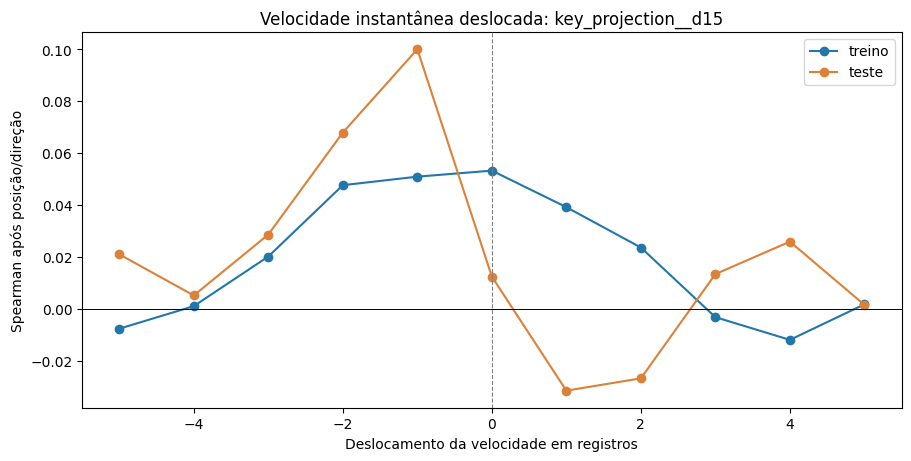

split,teste,treino
lag_records,,
-5,0.021,-0.008
-4,0.005,0.001
-3,0.029,0.020
-2,0.068,0.048
-1,0.100,0.051
0,0.012,0.053
1,-0.032,0.039
2,-0.027,0.024
3,0.013,-0.003


In [7]:
candidate = selected.iloc[0]['feature']
candidate_j = feature_cols.index(candidate)
lag_rows = []
for name,index in partitions.items():
    for lag in range(-5,6):
        valid = (t_index[index] + lag >= 0) & (t_index[index] + lag < len(speed))
        chosen = index[valid]
        design = spatial_direction_design(meta.iloc[chosen])
        regularizer = np.sqrt(1e-3)*np.eye(design.shape[1])
        augmented = np.vstack([design,regularizer])
        a = residual_features[name][valid,candidate_j]
        y = speed[t_index[chosen] + lag]
        beta = np.linalg.lstsq(augmented,np.r_[y,np.zeros(design.shape[1])],rcond=None)[0]
        ry = y-design@beta
        lag_rows.append((name,lag,float(spearmanr(a,ry).statistic)))
lag_scores = pd.DataFrame(lag_rows,columns=['split','lag_records','rho_adjusted'])
lag_scores.to_csv(notebook_csv_path('HardPos_speed_cells', 'HardPos_speed_cells_lags.csv'),index=False)
fig,ax=plt.subplots(figsize=(9,4.5),constrained_layout=True)
for name,color in [('treino','#2277aa'),('teste','#dc8137')]:
    part=lag_scores[lag_scores.split==name]
    ax.plot(part.lag_records,part.rho_adjusted,marker='o',label=name,color=color)
ax.axhline(0,color='black',lw=.7)
ax.axvline(0,color='gray',lw=.8,ls='--')
ax.set(xlabel='Deslocamento da velocidade em registros',ylabel='Spearman após posição/direção',
       title='Velocidade instantânea deslocada: '+candidate)
ax.legend()
fig.savefig(root/'imgs/hardpos_speed_cells_lags.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)
display(lag_scores.pivot(index='lag_records',columns='split',values='rho_adjusted').round(3))

## Como interpretar

Uma candidata a speed cell precisaria manter uma curva de ativação por velocidade no trecho reservado, uma correlação além dos efeitos de posição/direção e um resultado acima do controle temporal. Um decodificador populacional pode revelar informação distribuída mesmo quando nenhuma dimensão isolada apresenta esse padrão. Se esses critérios falharem, a conclusão é limitada a este checkpoint e a este protocolo; a representação de velocidade pode depender de outra tarefa de treino ou de dados com intervalo temporal mais regular.